# Anticipating a rival's pit window
IIT414W · Friday 16 October 2026 · 11:10–13:40

**Driving question:** Will this rival enter the pits within their next three laps?

Work in pairs, alternate operator/verifier, then submit your usual individual exit response. This is formative practice. The oral control on 23 October still covers material taught through 9 October only.

McLaren has described using AI to model competitors' behaviour ([source](https://www.mclaren.com/racing/formula-1/2019/canadian-grand-prix/how-make-right-call-safety-car/)). We test a small, observable part of that problem. An observed pit entry is different from an optimal strategic choice.

Use a number, explain what it means and state a limitation. Keep the current course AI policy. If saved outputs are already visible, describe your answer as an explanation after seeing the result rather than a prior prediction.


## A · What can we know at prediction time?
One row is a driver at the end of lap L. Positive means an observed pit entry in L+1, L+2 or L+3. These are the driver's laps, including for lapped cars. Cuts on pit-entry/exit laps or under SC/VSC/red are ineligible. An incomplete negative horizon is censored and excluded from model fitting.

**Before running:** Which fields would leak the answer: compound, last reported tyre age, event_s, or future_neutralisation? Explain when each becomes available.

**Response A:** [Write your explanation here.]


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score
from pitwindow_student_v2 import (FEATURES, fit_candidates, fit_historical_baseline,
    score_historical_baseline, choose_threshold, apply_policy)

data = pd.read_csv(Path('data')/'learning_v2.csv', dtype={'circuit_id':str,'driver_id':str})
train = data.loc[data.partition.eq('train')].copy()
dev = data.loc[data.partition.eq('development')].copy()
assert train.year.max() <= 2021
assert dev.year.eq(2022).all() and dev.round_number.le(11).all()
assert not data.partition.isin(['reserved_2022','historical_test','external_2026']).any()
data.groupby('partition').agg(rows=('y','size'), positive_windows=('y','sum'),
    distinct_pit_entries=('event_id','nunique'))


,rows,positive_windows,distinct_pit_entries
partition,,,
development,9451,1073.0,370
train,63165,5523.0,1934


The first eleven rounds of 2022 are development data. The remaining rounds are reserved for a later calibration lesson. Historical test data stay with the teacher. The 2026 file contains already frozen scores for interpretation, without predictors for fitting.

tyre_life is the last reported tyre-age count before the cut; it can lag the completed lap. We retain that reporting delay rather than correcting it with future messages. Current-car lap history and prior pit entries are available. No weather was used because it was absent in the 2026 cache.


In [2]:
pd.DataFrame({'feature': FEATURES, 'available_by_cut': [True]*len(FEATURES)})


,feature,available_by_cut
0,circuit_id,True
1,compound,True
2,tyre_life,True
3,lap_number,True
4,progress,True
5,prior_pit_entries,True
6,pace_median_s,True
7,pace_slope_s_per_lap,True
8,pace_n,True


## B · A serious baseline
The reference estimates historical pit-entry frequency from circuit, compound and reported tyre-age groups. Rates are smoothed toward broader groups using training opportunities, including rows with no pit entry.

**Before running:** Why can 'never alert' have high accuracy while identifying no pit entries?

**Response B:** [Use counts, not accuracy alone.]


In [3]:
baseline = fit_historical_baseline(train)
baseline_scores = score_historical_baseline(dev, baseline)
baseline_policy = choose_threshold(baseline_scores, dev)
positive = int(dev.y.sum())
pd.DataFrame([
    {'policy':'never alert','TP':0,'FP':0,'FN':positive,'alerts':0},
    {'policy':'always alert','TP':positive,'FP':len(dev)-positive,'FN':0,'alerts':len(dev)}
])


,policy,TP,FP,FN,alerts
0,never alert,0,0,1073,0
1,always alert,1073,8378,0,9451


## C · Why combine trees?
**Bagging:** bootstrap rows for each tree, then average leaf scores.
**Random Forest:** additionally sample candidate features at each node. This does not remove a column permanently.
**Boosting:** add stages that reduce the loss of the current ensemble; later stages depend on earlier predictions.

The two forests below have the same seed, 150 trees, maximum depth 6 and minimum leaf size 30. Only max_features changes: all candidates versus sqrt.

**Before running:** Predict how changing max_features might affect similarity among trees. Does lower similarity guarantee a better result?

**Response C:** With max_features = all, every split can pick the same strongest feature (e.g. tyre_life), so the trees end up very similar. With sqrt, each split only sees a random subset of features, so trees are more different and their errors average out better. Lower similarity does not guarantee a better result: each individual tree is weaker (it may miss the best feature at a split), so the gain depends on the data.

In [4]:
models = fit_candidates(train)
development_scores = {'historical_baseline': baseline_scores}
development_scores.update({name: model.predict_proba(dev[FEATURES])[:,1]
    for name, model in models.items()})
rows = []
for name, scores in development_scores.items():
    rule = choose_threshold(scores, dev)
    alerts = apply_policy(scores, rule)
    tp = int(((dev.y.to_numpy()==1)&alerts).sum())
    fp = int(((dev.y.to_numpy()==0)&alerts).sum())
    rows.append(dict(model_id=name, AP=average_precision_score(dev.y,scores),
        TP=tp, FP=fp, FN=int(dev.y.sum())-tp, alerts=int(alerts.sum()),
        precision=tp/alerts.sum() if alerts.any() else np.nan,
        events_caught=dev.loc[alerts & dev.y.eq(1),'event_id'].nunique()))
comparison = pd.DataFrame(rows)
comparison.to_csv('computed_development_v2.csv', index=False)
comparison


,model_id,AP,TP,FP,FN,alerts,precision,events_caught
0,historical_baseline,0.212913,250,681,823,931,0.268528,94
1,logistic,0.228173,248,695,825,943,0.262990,94
2,tree,0.179691,154,417,919,571,0.269702,63
3,forest_all,0.236137,259,679,814,938,0.276119,107
4,forest_sqrt,0.331293,340,605,733,945,0.359788,140
5,boost,0.258400,304,626,769,930,0.326882,131


Each policy uses a development alert budget of at most 10% of opportunities. That budget does not guarantee the same alert rate in later races. AP is an optional ranking summary; interpret the actual counts and distinct events first.

**Follow-up:** Compare forest_all and forest_sqrt. Name the single changed parameter, cite two numbers and explain why this result is not a universal guarantee.

The only changed parameter is max_features (all 9 features for forest_all vs sqrt ≈ 3 per split for forest_sqrt). With a similar number of alerts (938 vs 945), forest_sqrt caught 140 distinct entries vs 107 and made 605 false alerts vs 679. This is not a universal guarantee: it is one seed, one training set and one development split (early 2022), so with other data, seeds or hyperparameters the ranking could change.

## D · Changing the alert rule
Lowering a threshold changes alerts without retraining the forest. A model score is not automatically a calibrated probability. Several correct alerts can refer to one pit entry.

We selected the candidate and operational rule using early-2022 development only. Try another threshold on development scores and compare both false alarms and distinct entries caught.

**Response D:**

| threshold | alerts | FP | distinct entries caught (of 370) | false alerts / 100 opp. |
|---|---|---|---|---|
| 0.50 | 2569 | 1918 | 237 | 20.3 |
| 0.608 (original) | 945 | 605 | 140 | 6.4 |
| 0.62 (chosen) | 789 | 502 | 120 | 5.3 |

I chose 0.62. Going down to 0.5 catches ~100 more entries but triples the false alerts (about 1 false alarm every 5 opportunities), which a strategist would stop trusting. 0.62 removes 103 false alerts compared with the original, at the cost of 20 entries, keeping false alarms around 5 per 100 opportunities. Limitation: the score is not a probability and this was tuned on early-2022 only, so the alert rate may differ in later races.

After feedback: [write what your partner/teacher challenged and what you changed].

In [14]:
SELECTED_MODEL = 'forest_sqrt'
#THRESHOLD = 0.6082833509486985
THRESHOLD = 0.62
scores = development_scores[SELECTED_MODEL]
alerts = scores >= THRESHOLD
tp = int(((dev.y.to_numpy()==1)&alerts).sum())
fp = int(((dev.y.to_numpy()==0)&alerts).sum())
pd.Series({'threshold':THRESHOLD, 'alerts':int(alerts.sum()),'TP':tp,'FP':fp,
    'FN':int(dev.y.sum())-tp,
    'distinct_entries_caught':dev.loc[alerts & dev.y.eq(1),'event_id'].nunique(),
    'false_alerts_per_100_opportunities':100*fp/len(dev)})


threshold                               0.620000
alerts                                789.000000
TP                                    287.000000
FP                                    502.000000
FN                                    786.000000
distinct_entries_caught               120.000000
false_alerts_per_100_opportunities      5.311607
dtype: float64

## E · Does the frozen model transfer to 2026?
The following scores were computed after freezing model choice and thresholds. They cannot be changed by your development-threshold experiment above.

Compare the forest with the historical reference. Report alerts, entries caught and a limitation. More entries caught can come with more false alarms. An entry can be a repair or penalty, not necessarily a tyre-strategy decision.


In [7]:
external = pd.read_csv(Path('data')/'external_2026_frozen_v2.csv', dtype={'driver_id':str,'race_id':str})
summary = []
for name, g in external.groupby('model_id'):
    caught = g.loc[g.alert & g.y.eq(1)].sort_values('cut_s').drop_duplicates('event_id')
    summary.append(dict(model_id=name, AP=average_precision_score(g.y,g.score),
        alerts=int(g.alert.sum()), TP=int((g.alert & g.y.eq(1)).sum()),
        FP=int((g.alert & g.y.eq(0)).sum()), entries_caught=len(caught),
        eligible_entries=g.loc[g.y.eq(1),'event_id'].nunique(),
        median_first_warning_s=(caught.event_s-caught.cut_s).median()))
pd.DataFrame(summary)


,model_id,AP,alerts,TP,FP,entries_caught,eligible_entries,median_first_warning_s
0,forest_sqrt,0.243387,1243,320,923,115,347,284.6460
1,historical_baseline,0.158797,1224,218,1006,82,347,278.0465


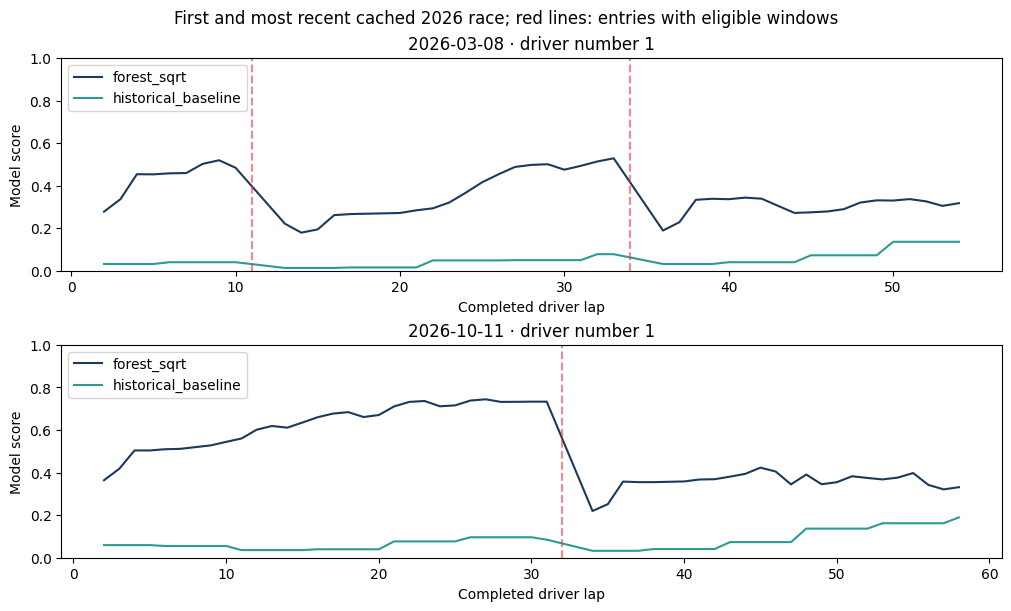

In [8]:
races = sorted(external.race_id.unique())
case_races = [races[0], races[-1]]
fig, axes = plt.subplots(2,1,figsize=(10,6),constrained_layout=True)
for ax, race_id in zip(axes, case_races):
    case = external.loc[external.race_id.eq(race_id)]
    driver = sorted(case.driver_id.unique(), key=lambda x: int(x))[0]
    case = case.loc[case.driver_id.eq(driver)].sort_values('lap_number')
    for name, color in [(SELECTED_MODEL,'#1A3A5C'),('historical_baseline','#2A9D8F')]:
        line = case.loc[case.model_id.eq(name)]
        ax.plot(line.lap_number,line.score,label=name,color=color)
    for pit_lap in case.event_lap.dropna().unique():
        ax.axvline(pit_lap,color='#E63946',alpha=.6,linestyle='--')
    ax.set(title=f'{race_id} · driver number {driver}',xlabel='Completed driver lap',ylabel='Model score',ylim=(0,1))
    ax.legend(loc='upper left')
fig.suptitle('First and most recent cached 2026 race; red lines: entries with eligible windows')
fig.savefig('race_windows_v2.png',dpi=160)
plt.show()


**Response E:** Yes, the frozen forest adds information over the reference. With almost the same number of alerts (1243 vs 1224), it caught 115 of 347 entries (33%) vs 82 (24%), with fewer false alerts (923 vs 1006). The median first warning is similar (~285 s vs ~278 s before the pit entry). Limitations: about 3 out of 4 alerts are still false; tyre_life is reported with a delay; and some entries may be repairs or penalties, not strategy decisions.

### Individual exit response · finish by 13:40
1. “Changing max_features affects how similar the trees are: with sqrt, each split sees a random subset of features, so trees are more diverse. Here forest_sqrt caught 140 entries vs 107 for forest_all, but this is one seed and one split, not a guarantee.”
2. “At my chosen threshold, 0.62, the forest makes 789 alerts and catches 120 of 370 entries with 5.3 false alerts per 100 opportunities; the trade-off is 20 fewer entries caught than at 0.608 in exchange for 103 fewer false alarms.”
3. “One pit entry can receive several alerts because the window is three laps, so the rows at L-1, L-2 and L-3 before the stop are all positive and can each trigger an alert (340 TP but only 140 distinct entries at 0.608).”
4. “Before recommending a real strategy decision, I would check that the alert rate holds on the reserved 2022 rounds, whether the score is calibrated, and whether the entry is a tyre stop rather than a repair or penalty.”

The classroom evidence is your explanation, controlled comparison and revised decision. Grammar is not the target of this exercise.